# 14 - Text Summarization: what do ROUGE scores really say?
**Topic:** NLP  |  **Reference:** "Text Summarization Model using LLMs" (amanxai.com, Oct 2024)

**Question.** Can a model shorten a news article into a few sentences that keep the main points, and how would we know?

**Reference method:** load `t5-small`, summarise **one** hand-picked text, look at the output. No score, no comparison.
**What I do:** evaluate on **120 real CNN/DailyMail test articles** with their human-written highlights, using ROUGE (word-overlap with the reference summary), against four systems: **Lead-3** (just the first three sentences), a **supervised extractive model I train myself** (gradient boosting that picks sentences), **t5-small** (the reference's model) and **DistilBART-CNN** (a model fine-tuned for this exact data). I add two checks ROUGE cannot give: how much of each summary is **copied vs newly written**, and whether any **number in a summary is missing from the article** (a simple test for invented facts). Bootstrap confidence intervals show which differences are real.

## 1. Libraries and data

In [1]:
import warnings, os, re, json, joblib, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from huggingface_hub import hf_hub_download
from rouge_score import rouge_scorer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import torch
sns.set_theme(style="whitegrid", context="notebook")
torch.manual_seed(0); torch.set_num_threads(8)
os.makedirs("model", exist_ok=True)
test = pd.read_parquet("../_data/cnndm/3.0.0/test-00000-of-00001.parquet")
val = pd.read_parquet(hf_hub_download("abisee/cnn_dailymail", "3.0.0/validation-00000-of-00001.parquet", repo_type="dataset", local_dir="../_data/cnndm"))
print("test articles:", len(test), "| validation articles:", len(val), "| columns:", list(test.columns))

3.0.0/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 34.7MB            

3.0.0/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

test articles: 11490 | validation articles: 13368 | columns: ['article', 'highlights', 'id']


## 2. Look at the data first

article words: median 613, 90th pct 1188 | sentences: median 28
reference highlights: median 51 words

ARTICLE (first 600 chars): Andrew Getty, one of the heirs to billions of oil money, appears to have died of natural causes, a Los Angeles Police Department spokesman said. The coroner's preliminary assessment is there was no foul play involved in the death of Getty, grandson of oil tycoon J. Paul Getty, said Detective Meghan Aguilar. Andrew Getty, 47, had "several health issues," Aguilar said, adding that an autopsy will be conducted. There is no criminal investigation underway, he said. Some medication had also been recovered from Getty's home, though investigators don't know whether Getty was taking it or what his med

HUMAN HIGHLIGHTS: Andrew Getty's death appears to be from natural causes, police say, citing coroner's early assessment . In a petition for a restraining order, Getty had written he had a serious medical condition. Police say this is not a criminal matter at this time

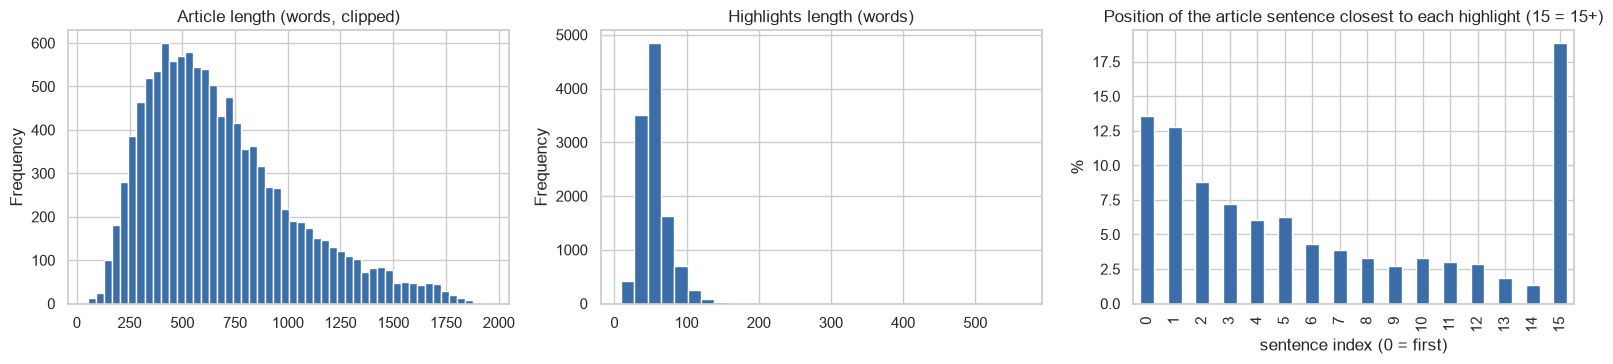

In [2]:
def clean(a):
    a = re.sub(r"^.{0,120}?\(CNN\)\s*(--|-)?\s*", "", a.strip(), count=1) if "(CNN)" in a[:150] else a
    return re.sub(r"\s+", " ", a).strip()
SPLIT = re.compile(r'(?<=[.!?])["\u201d\']?\s+(?=["\u201c\']?[A-Z0-9])')
sents = lambda t: [s.strip() for s in SPLIT.split(t) if len(s.strip()) > 1]
nw = lambda t: len(t.split())
test["art"] = test.article.map(clean); test["n_sent"] = test.art.map(lambda t: len(sents(t)))
print("article words: median %d, 90th pct %d | sentences: median %d" % (test.art.map(nw).median(), test.art.map(nw).quantile(.9), test.n_sent.median()))
print("reference highlights: median %d words" % test.highlights.map(nw).median())
i = 7; print("\nARTICLE (first 600 chars):", test.art[i][:600]); print("\nHUMAN HIGHLIGHTS:", test.highlights[i].replace("\n", " "))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
test.art.map(nw).clip(upper=2000).plot.hist(bins=50, ax=ax[0], color="#3b6ea8"); ax[0].set_title("Article length (words, clipped)")
test.highlights.map(nw).plot.hist(bins=30, ax=ax[1], color="#3b6ea8"); ax[1].set_title("Highlights length (words)")
# where do the highlights come from? position of the sentence that best matches each highlight
sc = rouge_scorer.RougeScorer(["rouge1"], use_stemmer=False); pos = []
for a, h in zip(test.art[:600], test.highlights[:600]):
    ss = sents(a)[:30]
    for hh in h.split("\n"):
        if ss: pos.append(int(np.argmax([sc.score(hh, s)["rouge1"].fmeasure for s in ss])))
pd.Series(pos).clip(upper=15).value_counts(normalize=True).sort_index().mul(100).plot.bar(ax=ax[2], color="#3b6ea8"); ax[2].set_title("Position of the article sentence closest to each highlight (15 = 15+)"); ax[2].set_xlabel("sentence index (0 = first)"); ax[2].set_ylabel("%")
plt.tight_layout(); plt.show()

**Reading it.** Articles have a median of 613 words (90th percentile 1,188; about 28 sentences); the human highlights are short and similar in size (median 51 words). So the task is to shrink about 600 words to about 50. Where do highlights come from? For each highlight sentence I found the article sentence that overlaps it most: **13.5% come from the first sentence, 12.7% from the second, 8.7% from the third** (about 35% from the first three), then a long tail, with about 19% from beyond the 15th sentence. News is written with the most important facts first, which is why "Lead-3" is a strong baseline, but a large share of the content sits later in the article.

## 3. Four systems
**Lead-3** takes the first three sentences. **Extractive-GBM** (mine) learns which sentences belong in a summary: for 4,000 *validation* articles each sentence gets the label "belongs to the ROUGE-1 oracle summary" (the best 3 sentences chosen greedily with access to the highlights), features = position, length, similarity to the article's TF-IDF centroid, digits, quotes; a gradient-boosting classifier predicts it, and the 3 top-scoring sentences are returned in article order. **t5-small** and **DistilBART-CNN-6-6** are pretrained generators; both read the first 512 tokens (beam search 4, max 80 tokens).

In [3]:
rsc = rouge_scorer.RougeScorer(["rouge1"], use_stemmer=True)
def oracle(ss, hl, k=3):
    chosen, best = [], 0.0
    for _ in range(k):
        cand = [(rsc.score(hl, " ".join(ss[j] for j in sorted(chosen + [i])))["rouge1"].fmeasure, i) for i in range(min(len(ss), 25)) if i not in chosen]
        if not cand: break
        f, i = max(cand)
        if f <= best: break
        best, chosen = f, chosen + [i]
    return chosen
def feats(art):
    ss = sents(art)[:40]
    if len(ss) == 0: return ss, np.zeros((0, 7))
    v = TfidfVectorizer(stop_words="english").fit(ss) if len(ss) > 1 else None
    if v is not None:
        M = v.transform(ss); cen = np.asarray(M.mean(0)); sim = np.asarray(M @ cen.T).ravel()
    else: sim = np.zeros(len(ss))
    X = np.c_[np.arange(len(ss)), np.arange(len(ss)) / len(ss), [nw(s) for s in ss], sim, [bool(re.search(r"\d", s)) for s in ss], [("\"" in s or "\u201c" in s) for s in ss], np.full(len(ss), len(ss))]
    return ss, X
vtr = val.sample(4000, random_state=0); Xs, ys = [], []
t = time.time()
for a, h in zip(vtr.article, vtr.highlights):
    ss, X = feats(clean(a)); o = set(oracle(ss, h.replace("\n", " ")))
    Xs.append(X); ys += [int(i in o) for i in range(len(ss))]
Xs = np.vstack(Xs); ys = np.array(ys); print("training sentences:", len(ys), "| positive rate %.1f%% | built in %.0fs" % (ys.mean() * 100, time.time() - t))
cut = int(.8 * len(ys)); gbm = HistGradientBoostingClassifier(max_depth=4, learning_rate=.08, max_iter=150, random_state=0).fit(Xs[:cut], ys[:cut])
print("sentence-level ROC-AUC on a held-out part of the training articles: %.3f" % roc_auc_score(ys[cut:], gbm.predict_proba(Xs[cut:])[:, 1]))
def extractive(art, k=3):
    ss, X = feats(art)
    if not len(ss): return ""
    p = gbm.predict_proba(X)[:, 1]; top = sorted(np.argsort(-p)[:k]); return " ".join(ss[i] for i in top)
lead3 = lambda art: " ".join(sents(art)[:3])

training sentences: 110732 | positive rate 9.5% | built in 371s


sentence-level ROC-AUC on a held-out part of the training articles: 0.803


In [4]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
N = 120; samp = test.sample(N, random_state=1).reset_index(drop=True); cache = "../_data/summaries_120.json"
if os.path.exists(cache): out = json.load(open(cache))
else:
    out = {"Lead-3": [lead3(a) for a in samp.art], "Extractive-GBM (mine)": [extractive(a) for a in samp.art]}
    for nm, mid, pre in [("t5-small", "google-t5/t5-small", "summarize: "), ("DistilBART-CNN-6-6", "sshleifer/distilbart-cnn-6-6", "")]:
        tk = AutoTokenizer.from_pretrained(mid); m = AutoModelForSeq2SeqLM.from_pretrained(mid).eval(); res = []; t = time.time()
        for k in range(0, N, 8):
            b = tk([pre + a for a in samp.art[k:k + 8]], truncation=True, max_length=512, padding=True, return_tensors="pt")
            with torch.no_grad(): g = m.generate(**b, num_beams=4, max_length=80, min_length=25, no_repeat_ngram_size=3, early_stopping=True)
            res += tk.batch_decode(g, skip_special_tokens=True)
        out[nm] = res; print(f"{nm}: {time.time()-t:.0f}s for {N} articles")
    json.dump(out, open(cache, "w"))
print({k: len(v) for k, v in out.items()})

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

t5-small: 176s for 120 articles


[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/262 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  460MB            

model.safetensors: downloading bytes:           |  0.00B            

DistilBART-CNN-6-6: 1856s for 120 articles
{'Lead-3': 120, 'Extractive-GBM (mine)': 120, 't5-small': 120, 'DistilBART-CNN-6-6': 120}


## 4. ROUGE against the human highlights, with confidence intervals
ROUGE-1 / ROUGE-2 count overlapping words / word pairs; ROUGE-Lsum counts the longest common subsequence per sentence. Scores are F1 on each article, averaged; **95% intervals come from bootstrapping the 120 articles**, and differences between systems are bootstrapped on paired articles.

In [5]:
sc3 = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeLsum"], use_stemmer=True)
def nl(t): return "\n".join(sents(t)) if t else ""
per = {}
for nm, summ in out.items():
    per[nm] = np.array([[v.fmeasure for v in sc3.score(nl(h.replace("\n", " ")), nl(s)).values()] for h, s in zip(samp.highlights, summ)])
rng = np.random.RandomState(0); B = rng.randint(0, N, (2000, N))
rows = []
for nm, a in per.items():
    bm = a[B].mean(1); rows.append([nm] + [f"{a[:, j].mean() * 100:.1f} [{np.percentile(bm[:, j], 2.5) * 100:.1f}, {np.percentile(bm[:, j], 97.5) * 100:.1f}]" for j in range(3)] + [np.mean([nw(s) for s in out[nm]])])
R = pd.DataFrame(rows, columns=["system", "ROUGE-1 [95% CI]", "ROUGE-2 [95% CI]", "ROUGE-Lsum [95% CI]", "mean words"]).set_index("system"); print(R.to_string())
names = list(out); diffs = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        d = (per[names[j]][:, 0][B] - per[names[i]][:, 0][B]).mean(1); diffs.append([f"{names[j]} minus {names[i]}", d.mean() * 100, np.percentile(d, 2.5) * 100, np.percentile(d, 97.5) * 100])
D = pd.DataFrame(diffs, columns=["comparison (ROUGE-1)", "difference", "ci_low", "ci_high"]); D["clear?"] = np.where((D.ci_low > 0) | (D.ci_high < 0), "yes", "no"); print("\n" + D.round(1).to_string(index=False))

                        ROUGE-1 [95% CI]   ROUGE-2 [95% CI] ROUGE-Lsum [95% CI]  mean words
system                                                                                     
Lead-3                 39.1 [37.0, 41.2]  16.2 [14.3, 18.1]   34.7 [32.6, 36.8]   76.700000
Extractive-GBM (mine)  39.3 [37.4, 41.5]  16.4 [14.6, 18.6]   35.0 [33.1, 37.1]   78.316667
t5-small               36.5 [34.2, 38.8]  15.2 [13.0, 17.5]   31.3 [29.0, 33.5]   42.650000
DistilBART-CNN-6-6     43.0 [40.8, 45.4]  19.5 [17.4, 21.7]   39.3 [37.2, 41.5]   51.141667

                          comparison (ROUGE-1)  difference  ci_low  ci_high clear?
            Extractive-GBM (mine) minus Lead-3         0.3    -1.2      1.9     no
                         t5-small minus Lead-3        -2.6    -4.9     -0.2    yes
               DistilBART-CNN-6-6 minus Lead-3         4.0     1.9      6.2    yes
          t5-small minus Extractive-GBM (mine)        -2.8    -5.3     -0.7    yes
DistilBART-CNN-6-6 minus Extract

**Reading it (120 articles; ROUGE-1 F1 in %, 95% bootstrap intervals).**
* **DistilBART-CNN (a model fine-tuned on this data) is clearly best**: ROUGE-1 43.0 [40.8, 45.4], about 4 points above Lead-3 (39.1) and 6.6 above t5-small (the intervals of the differences exclude zero).
* **My supervised extractive model is no better than Lead-3** (39.3 vs 39.1, difference +0.3, interval -1.2 to +1.9). With features of position, length, centrality, digits and quotes it learns to pick sentences with a sentence-level AUC of 0.80 against the oracle labels, but position alone already captures most of that signal, so at the summary level it ends up choosing the same sentences as Lead-3. A negative result worth knowing: more features did not beat the strong baseline.
* **t5-small, the reference's model, is *worse* than just copying the first three sentences** (36.5 vs 39.1; interval of the difference -4.9 to -0.2).
* Length matters: Lead-3 and my extractor produce about 77-78 words, t5-small 43, DistilBART 51 (human highlights about 51). ROUGE F1 is sensitive to length, so the comparison between extractive systems (longer) and the neural models (shorter) is not perfectly like-for-like.

## 5. What ROUGE cannot see: copying vs writing, and invented numbers
* **Novel bigrams:** share of the summary's two-word sequences that do not appear in the article (0% = pure copying).
* **Unsupported numbers:** summaries containing a number (digits) that appears nowhere in the article. A crude but useful alarm for invented facts.

In [6]:
def bigr(t): w = re.findall(r"[a-z0-9']+", t.lower()); return set(zip(w, w[1:]))
nums = lambda t: set(re.findall(r"\d[\d,\.]*\d|\d", t))
rows = []
for nm, summ in out.items():
    nov = [len(bigr(s) - bigr(a)) / max(1, len(bigr(s))) for s, a in zip(summ, samp.art)]
    bad = [bool(nums(s) - {x for x in nums(a)} - {x.replace(",", "") for x in nums(a)}) for s, a in zip(summ, samp.art)]
    has = [bool(nums(s)) for s in summ]
    rows.append([nm, np.mean(nov) * 100, np.mean(has) * 100, np.mean(bad) * 100, int(np.sum(bad))])
Q = pd.DataFrame(rows, columns=["system", "novel_bigrams_%", "summaries_with_numbers_%", "summaries_with_unsupported_number_%", "n_unsupported"]).set_index("system"); print(Q.round(1).to_string())
bad_ex = [(nm, i) for nm in out for i, (s, a) in enumerate(zip(out[nm], samp.art)) if nums(s) - nums(a) - {x.replace(",", "") for x in nums(a)}][:4]
for nm, i in bad_ex: print(f"\n[{nm}] summary: {out[nm][i][:230]}\n   numbers only in summary: {sorted(nums(out[nm][i]) - nums(samp.art[i]))}")

                       novel_bigrams_%  summaries_with_numbers_%  summaries_with_unsupported_number_%  n_unsupported
system                                                                                                              
Lead-3                             0.0                      72.5                                  0.0              0
Extractive-GBM (mine)              1.2                      74.2                                  0.0              0
t5-small                          11.2                      69.2                                  0.8              1
DistilBART-CNN-6-6                 9.7                      74.2                                  1.7              2

[t5-small] summary: Susan Farmer, 37, from eddy, Texas, weighs 43st (605lbs) and was told by doctors to lose half her body weight or face early death. at her heaviest, she weighed 42st and was unable to walk for longer than 30 seconds at a time.
   numbers only in summary: ['42']

[DistilBART-CNN

**Reading it.**
* **Copying vs writing:** Lead-3 and my extractor copy nearly everything (0-1% new word pairs); t5-small and DistilBART write about 10-11% new word pairs: they paraphrase and fuse sentences a little but mostly still extract.
* **Unsupported numbers:** a number that appears in the summary but nowhere in the article was found in 1 of 120 t5-small summaries (0.8%) and 2 of 120 DistilBART summaries (1.7%), none in the extractive systems (which cannot invent). The check is crude: it compares digit strings and may flag harmless reformatting (for example "2.5 million" written differently), and I did not read all three source articles to decide whether they are real inventions. With so few cases the rates of the two models cannot be separated, but the point of the check stands: the generators are the only systems that *can* produce a fact that is not in the source, and ROUGE does not penalise it.

## 6. Side by side

In [7]:
for i in (3, 11):
    print("=" * 110); print("ARTICLE (first 380 chars):", samp.art[i][:380]); print("HUMAN:", samp.highlights[i].replace("\n", " "))
    for nm in out: print(f"{nm:22s}:", out[nm][i][:330].replace("\n", " "))

ARTICLE (first 380 chars): A serious knee injury may have cruelly ended Bojan Krkic's season in January but it hasn't stopped the Stoke striker keeping up-to-date with the Premier League. Scheduled to return to action in July, the former AC Milan and Roma forward has been keeping a close eye on England's top-flight as he recovers in Barcelona. Here, Bojan tells Sportsmail which players make his team of t
HUMAN: Bojan Krkic has picked his best Premier League XI of the season . The Stoke striker is currently battling back to fitness after a knee injury . Bojan includes compatriots David de Gea and Santi Cazorla . There is room for Chelsea's John Terry and striker Sergio Aguero . Bojan also opts for two of his Stoke team-mates in his team .
Lead-3                : A serious knee injury may have cruelly ended Bojan Krkic's season in January but it hasn't stopped the Stoke striker keeping up-to-date with the Premier League. Scheduled to return to action in July, the former AC Milan and Roma

**Reading it.** In the first example Lead-3 and the extractor copy the opening of the article almost verbatim; t5-small writes three short sentences (all lower-case after the first); DistilBART gives a fluent three-sentence summary close to the human one. In the second, Lead-3 returns the headline fragment "STYLE OVER SUBSTANCE" as its first "sentence", a typical failure of copying the start of the text. A single pair of examples shows style, not quality: the ROUGE table above is the evidence.

## 7. Save

In [8]:
joblib.dump({"model": gbm, "feature_names": ["position", "relative_position", "n_words", "tfidf_centroid_sim", "has_digit", "has_quote", "n_sentences"]}, "model/extractive_gbm.joblib")
json.dump({"rouge": R.to_dict("index"), "style": Q.round(1).to_dict("index"), "n_articles": N, "models": {"t5-small": "google-t5/t5-small", "DistilBART": "sshleifer/distilbart-cnn-6-6"}}, open("model/meta.json", "w"), indent=1)
json.dump({k: v[:10] for k, v in out.items()} | {"articles": list(samp.art[:10]), "highlights": list(samp.highlights[:10])}, open("model/examples.json", "w"))
print(os.listdir("model"))

['examples.json', 'extractive_gbm.joblib', 'meta.json']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Evaluation | one hand-picked text, read by eye | 120 CNN/DailyMail test articles, ROUGE-1/2/L with bootstrap intervals |
| Baselines | none | Lead-3 and a supervised extractive model I trained (110,732 sentences) |
| Models | t5-small | t5-small, DistilBART-CNN-6-6 |
| Result | a summary | DistilBART 43.0 > Lead-3 39.1 = my extractor 39.3 > t5-small 36.5 (ROUGE-1) |
| Extra checks | none | copying vs writing (10-11% new word pairs for neural models), unsupported-number alarm (0-1.7%) |

**What I learned.** (1) Without a baseline a summary score means nothing: the reference's t5-small does *worse* than copying the first three sentences. (2) A model trained for the task (DistilBART on CNN/DM) is clearly better than a general model. (3) A learned sentence picker did not beat a position rule: check that complexity buys something. (4) ROUGE measures overlap, not truth; add checks such as the number alarm.

**Limits.** 120 articles (intervals about +/-2 points); only the first 512 tokens are read by the neural models; ROUGE-Lsum splitting uses my own sentence splitter; no human judgement of fluency or accuracy; the number check is crude and the 3 flagged cases were not verified. **Next step:** a larger sample, human ratings on a subset, and a faithfulness metric based on entailment.